# step02_temporal_patterns — Temporal Editing Patterns

Measure annual and monthly activity, detect article-specific spikes, and document the limits on explaining them.

Run cells from top to bottom. Shared helpers and file paths are in `analysis_common.py`. Outputs go to `analysis_results/` and `figures/`.

,year,revisions
6,2007,37950
7,2008,22668
8,2009,17585
9,2010,14260
10,2011,17506
11,2012,12105
12,2013,9299
13,2014,8127
14,2015,8427
15,2016,5902


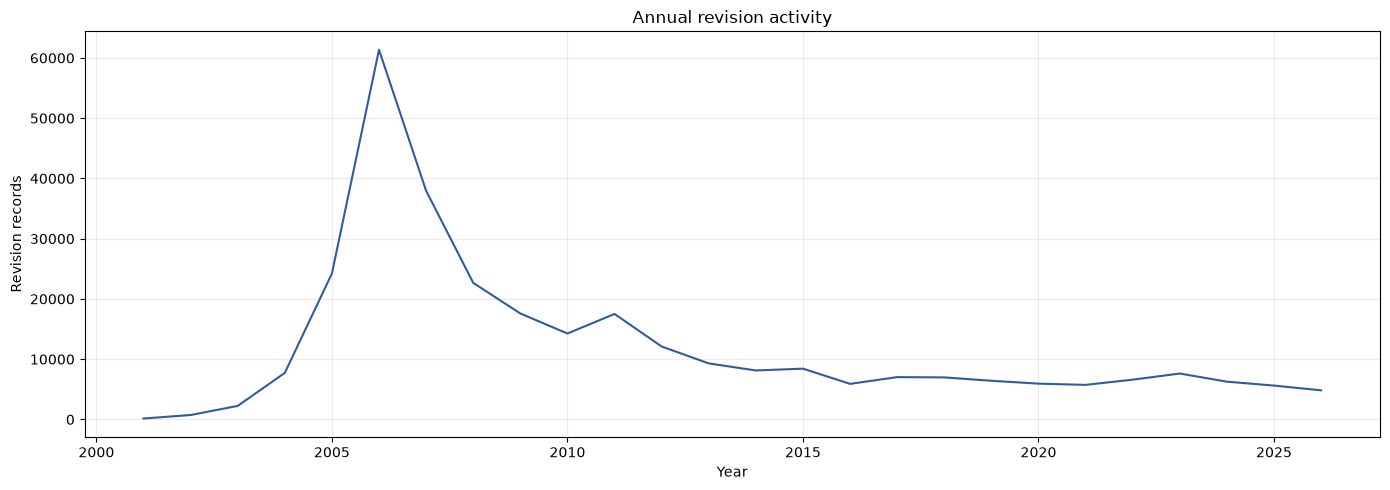

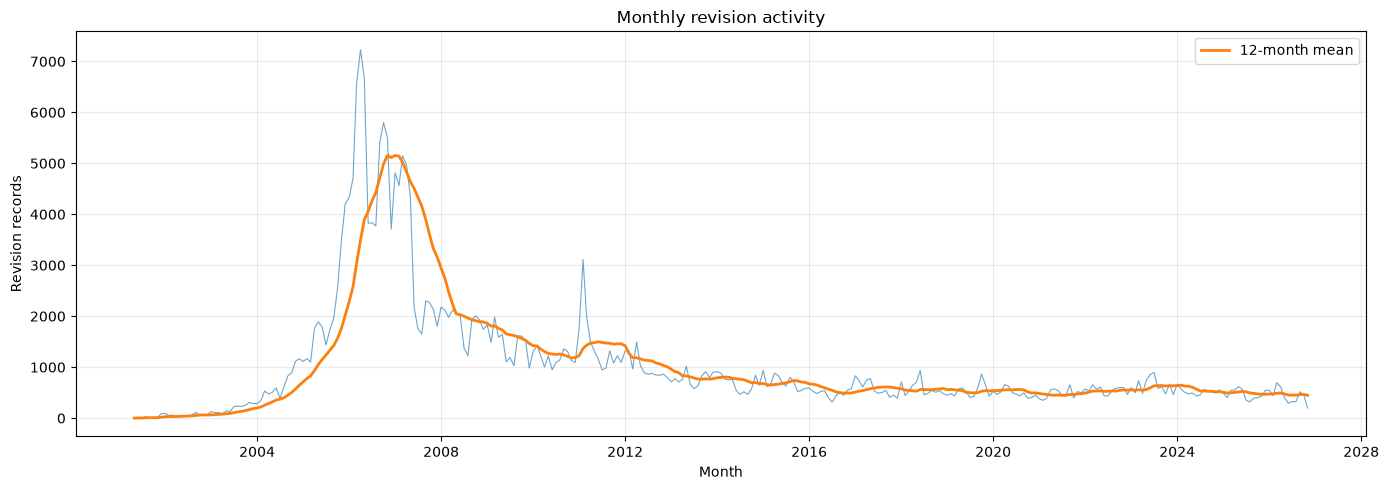

In [1]:
from pathlib import Path
import sys
from IPython.display import display
ROOT = Path.cwd().resolve()
while not (ROOT / 'analysis' / 'analysis_common.py').exists() and ROOT.parent != ROOT: ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'analysis'))
from analysis_common import *
df = load_revisions()
monthly = monthly_activity(df)
monthly['year'] = monthly.timestamp.dt.year
monthly['month'] = monthly.timestamp.dt.month
annual = df.dropna(subset=['timestamp']).groupby([df.timestamp.dt.year.rename('year'),'article_title']).size().rename('revisions').reset_index()
overall_annual = annual.groupby('year',as_index=False).revisions.sum()
save_table(monthly,'step02_monthly_activity_by_article.csv'); save_table(annual,'step02_annual_activity_by_article.csv'); save_table(overall_annual,'step02_annual_activity.csv')
display(overall_annual.tail(20))
fig, ax=plt.subplots(figsize=(14,5)); ax.plot(overall_annual.year,overall_annual.revisions,color='#315c9b'); ax.set(title='Annual revision activity',xlabel='Year',ylabel='Revision records'); ax.grid(alpha=.25); finish_plot(fig,'step02_annual_activity.png')
overall_monthly = monthly.groupby('timestamp',as_index=False).revisions.sum()
fig, ax=plt.subplots(figsize=(14,5)); ax.plot(overall_monthly.timestamp,overall_monthly.revisions,lw=.8,alpha=.65); ax.plot(overall_monthly.timestamp,overall_monthly.revisions.rolling(12,min_periods=1).mean(),lw=2,label='12-month mean'); ax.set(title='Monthly revision activity',xlabel='Month',ylabel='Revision records'); ax.legend(); ax.grid(alpha=.25); finish_plot(fig,'step02_monthly_activity.png')


In [2]:
spikes = robust_spikes(monthly).sort_values(['is_spike','revisions'],ascending=[False,False])
spikes.to_csv(OUTPUT_DIR/'step02_article_monthly_spikes.csv',index=False)
display(spikes[spikes.is_spike].head(30))
# Compare article start-to-end activity using first and last calendar-year counts.
annual_by_article = annual.sort_values(['article_title','year'])
trend_rows=[]
for article,g in annual_by_article.groupby('article_title'):
    first,last=g.iloc[0],g.iloc[-1]
    trend_rows.append({'article_title':article,'first_observed_year':int(first.year),'last_observed_year':int(last.year),'first_year_revisions':int(first.revisions),'last_year_revisions':int(last.revisions),'first_vs_last_year_ratio':(last.revisions/first.revisions if first.revisions else np.nan),'observed_years':int(g.year.nunique())})
trends=pd.DataFrame(trend_rows).sort_values('observed_years',ascending=False)
save_table(trends,'step02_long_term_trends.csv'); display(trends)


,article_title,timestamp,revisions,year,month,article_median,robust_threshold,is_spike
605,Arab Spring,2011-02-01 00:00:00+00:00,2050,2011,2,16.0,60.4780,True
8409,World War II,2006-04-01 00:00:00+00:00,1588,2006,4,40.0,128.9560,True
8408,World War II,2006-03-01 00:00:00+00:00,1333,2006,3,40.0,128.9560,True
606,Arab Spring,2011-03-01 00:00:00+00:00,1046,2011,3,16.0,60.4780,True
8414,World War II,2006-09-01 00:00:00+00:00,1022,2006,9,40.0,128.9560,True
6970,September 11 attacks,2006-09-01 00:00:00+00:00,865,2006,9,35.0,128.4038,True
8413,World War II,2006-08-01 00:00:00+00:00,849,2006,8,40.0,128.9560,True
8407,World War II,2006-02-01 00:00:00+00:00,848,2006,2,40.0,128.9560,True
8405,World War II,2005-12-01 00:00:00+00:00,769,2005,12,40.0,128.9560,True
8108,World War I,2006-04-01 00:00:00+00:00,761,2006,4,33.0,108.6126,True


,article_title,first_observed_year,last_observed_year,first_year_revisions,last_year_revisions,first_vs_last_year_ratio,observed_years
0,American Civil War,2001,2026,3,256,85.333333,26
1,American Revolution,2001,2026,1,339,339.000000,26
6,Black Death,2001,2026,21,124,5.904762,26
5,Battle of Gettysburg,2001,2026,30,43,1.433333,26
14,Great Depression,2001,2026,3,58,19.333333,26
10,Cuban Missile Crisis,2001,2026,3,150,50.000000,26
7,Boston Tea Party,2001,2026,5,70,14.000000,26
12,Emancipation Proclamation,2001,2026,2,51,25.500000,26
24,Russian Revolution,2001,2026,2,38,19.000000,26
25,September 11 attacks,2001,2026,10,477,47.700000,26


## Context investigation

The spike table is a statistical screen, not an explanation. Select candidate rows above, then record external research here. Do not describe an anniversary or current event as the cause unless an independent, dated source supports the connection. The CSV below deliberately marks context as unverified until a source is added.

In [3]:
context = spikes[spikes.is_spike].nlargest(20,'revisions')[['article_title','timestamp','revisions','article_median','robust_threshold']].copy()
context['context_claim']=''
context['source_title']=''
context['source_url']=''
context['source_date']=''
context['assessment']='Uninvestigated; correlation does not establish cause'
save_table(context,'step02_spike_context_review.csv'); display(context)


,article_title,timestamp,revisions,article_median,robust_threshold,context_claim,source_title,source_url,source_date,assessment
605,Arab Spring,2011-02-01 00:00:00+00:00,2050,16.0,60.4780,,,,,Uninvestigated; correlation does not establish...
8409,World War II,2006-04-01 00:00:00+00:00,1588,40.0,128.9560,,,,,Uninvestigated; correlation does not establish...
8408,World War II,2006-03-01 00:00:00+00:00,1333,40.0,128.9560,,,,,Uninvestigated; correlation does not establish...
606,Arab Spring,2011-03-01 00:00:00+00:00,1046,16.0,60.4780,,,,,Uninvestigated; correlation does not establish...
8414,World War II,2006-09-01 00:00:00+00:00,1022,40.0,128.9560,,,,,Uninvestigated; correlation does not establish...
6970,September 11 attacks,2006-09-01 00:00:00+00:00,865,35.0,128.4038,,,,,Uninvestigated; correlation does not establish...
8413,World War II,2006-08-01 00:00:00+00:00,849,40.0,128.9560,,,,,Uninvestigated; correlation does not establish...
8407,World War II,2006-02-01 00:00:00+00:00,848,40.0,128.9560,,,,,Uninvestigated; correlation does not establish...
8405,World War II,2005-12-01 00:00:00+00:00,769,40.0,128.9560,,,,,Uninvestigated; correlation does not establish...
8108,World War I,2006-04-01 00:00:00+00:00,761,33.0,108.6126,,,,,Uninvestigated; correlation does not establish...


In [4]:
# Add one independently sourced contextual example without treating it as causal proof.
candidate = spikes[(spikes.article_title.eq('Arab Spring')) & pd.to_datetime(spikes.timestamp).dt.strftime('%Y-%m').eq('2011-02')]
if not candidate.empty:
    record = candidate.nlargest(1, 'revisions')[['article_title','timestamp','revisions','article_median','robust_threshold']].iloc[0].to_dict()
    record.update({'context_claim':'The 2011 wave of protests is documented in historical timelines; February included key developments in Egypt. This is contemporaneous context, not proof that protests caused the Wikipedia spike.', 'source_title':'EU Institute for Security Studies, Timeline 2011', 'source_url':'https://www.iss.europa.eu/sites/default/files/3.1__Timeline_2011.pdf', 'source_date':'2011 timeline', 'assessment':'Temporal context independently documented; causal relationship unproven'})
    context = pd.concat([context[~((context.article_title.eq('Arab Spring')) & pd.to_datetime(context.timestamp).dt.strftime('%Y-%m').eq('2011-02'))], pd.DataFrame([record])], ignore_index=True)
save_table(context, 'step02_spike_context_review.csv'); display(context[context.source_url.ne('')])


,article_title,timestamp,revisions,article_median,robust_threshold,context_claim,source_title,source_url,source_date,assessment
19,Arab Spring,2011-02-01 00:00:00+00:00,2050,16.0,60.478,The 2011 wave of protests is documented in his...,"EU Institute for Security Studies, Timeline 2011",https://www.iss.europa.eu/sites/default/files/...,2011 timeline,Temporal context independently documented; cau...
